# Visualization Notebook

This notebook reproduces the same analysis and plots from `plot_results.py`, organized into notebook-friendly sections.

## 1) Imports and Plot Style

In [31]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.cm as cm
import matplotlib.colorbar as mcolorbar
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

COLORS = {
    "dp": "#2196F3",   # blue
    "tp": "#4CAF50",   # green
    "pp": "#FF9800",   # orange
    "mixed": "#9C27B0" # purple
}
PLOTS_DIR = os.path.join(os.getcwd(), "plots")
os.makedirs(PLOTS_DIR, exist_ok=True)
print(f"Saving plots to: {PLOTS_DIR}")


Saving plots to: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/plots


## 2) Load CSVs and Compute Power Statistics

In [32]:
BASE = os.getcwd()
DATA_DIR = os.path.join(BASE, "data")

configs = {
    "tp1_pp1_dp4": {"tp": 1, "pp": 1, "dp": 4, "file": "tp1_pp1_dp4_power.csv"},
    "tp4_pp1_dp1": {"tp": 4, "pp": 1, "dp": 1, "file": "tp4_pp1_dp1_power.csv"},
    "tp1_pp4_dp1": {"tp": 1, "pp": 4, "dp": 1, "file": "tp1_pp4_dp1_power.csv"},
    "tp2_pp2_dp1": {"tp": 2, "pp": 2, "dp": 1, "file": "tp2_pp2_dp1_power.csv"},
    "tp2_pp1_dp2": {"tp": 2, "pp": 1, "dp": 2, "file": "tp2_pp1_dp2_power.csv"},
    "tp1_pp2_dp2": {"tp": 1, "pp": 2, "dp": 2, "file": "tp1_pp2_dp2_power.csv"},
}

for name, cfg in configs.items():
    path = os.path.join(DATA_DIR, cfg["file"])
    df = pd.read_csv(path)
    df.columns = [
        "timestamp", "total_power_W",
        "GPU_0_W", "GPU_1_W", "GPU_2_W", "GPU_3_W"
    ]

    warmup = int(len(df) * 0.2)
    steady = df.iloc[warmup:]

    cfg["avg_power"] = steady["total_power_W"].mean()
    cfg["peak_power"] = steady["total_power_W"].max()
    cfg["df"] = df

    print(f"{name}: avg={cfg['avg_power']:.1f}W  peak={cfg['peak_power']:.1f}W  samples={len(steady)}")

tp1_pp1_dp4: avg=353.5W  peak=627.8W  samples=1560
tp4_pp1_dp1: avg=370.4W  peak=527.9W  samples=1036
tp1_pp4_dp1: avg=264.5W  peak=658.7W  samples=177
tp2_pp2_dp1: avg=372.6W  peak=601.2W  samples=108
tp2_pp1_dp2: avg=272.6W  peak=692.6W  samples=200
tp1_pp2_dp2: avg=372.1W  peak=728.0W  samples=81


# Power consumption trend during training (including warmup phase)

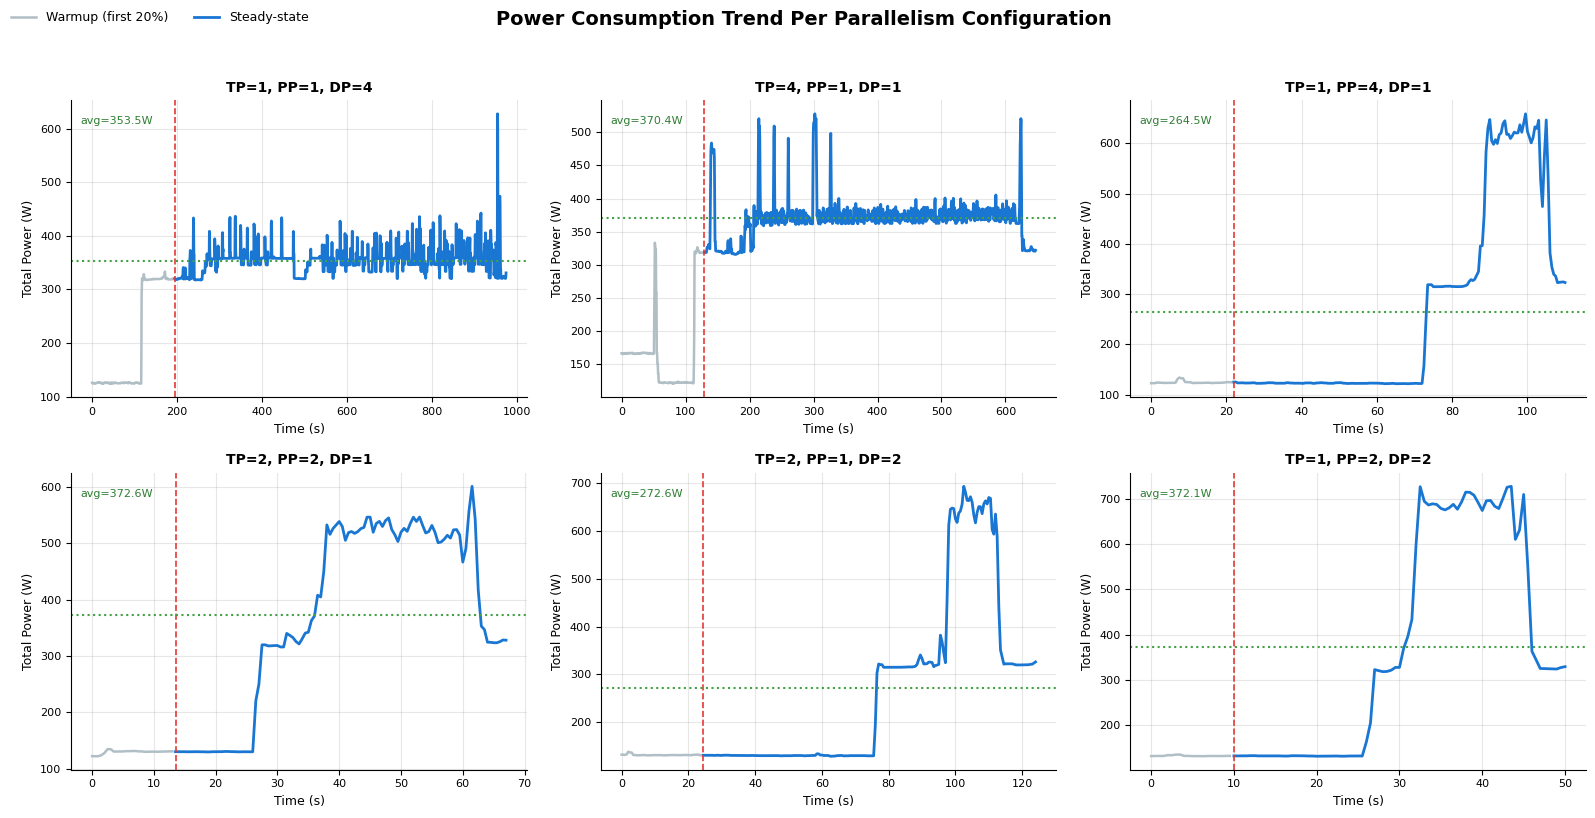

In [33]:
# Power trend plot for each configuration, highlighting warmup vs steady-state.
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=False, sharey=False)
axes = axes.flatten()

for ax, (name, cfg) in zip(axes, configs.items()):
    df = cfg["df"].copy()
    warmup_idx = int(len(df) * 0.2)

    x = np.arange(len(df)) * 0.5  # seconds (INTERVAL is defined later)
    y = df["total_power_W"].to_numpy()

    ax.plot(x[:warmup_idx], y[:warmup_idx], color="#B0BEC5", linewidth=1.8, label="Warmup (first 20%)")
    ax.plot(x[warmup_idx:], y[warmup_idx:], color="#1976D2", linewidth=2.0, label="Steady-state")

    ax.axvline(x[warmup_idx] if warmup_idx < len(x) else x[-1], color="#E53935", linestyle="--", linewidth=1.2)
    ax.axhline(cfg["avg_power"], color="#43A047", linestyle=":", linewidth=1.5)

    ax.set_title(f"TP={cfg['tp']}, PP={cfg['pp']}, DP={cfg['dp']}", fontsize=10, fontweight="bold")
    ax.set_xlabel("Time (s)", fontsize=9)
    ax.set_ylabel("Total Power (W)", fontsize=9)
    ax.tick_params(labelsize=8)

    ax.text(0.02, 0.92, f"avg={cfg['avg_power']:.1f}W", transform=ax.transAxes, fontsize=8, color="#2E7D32")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", ncol=4, fontsize=9, frameon=False)
fig.suptitle("Power Consumption Trend Per Parallelism Configuration", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "graph0_power_trends_with_warmup.png"), dpi=150, bbox_inches="tight")
plt.show()

# Carbon trends during all training including warmpup phase

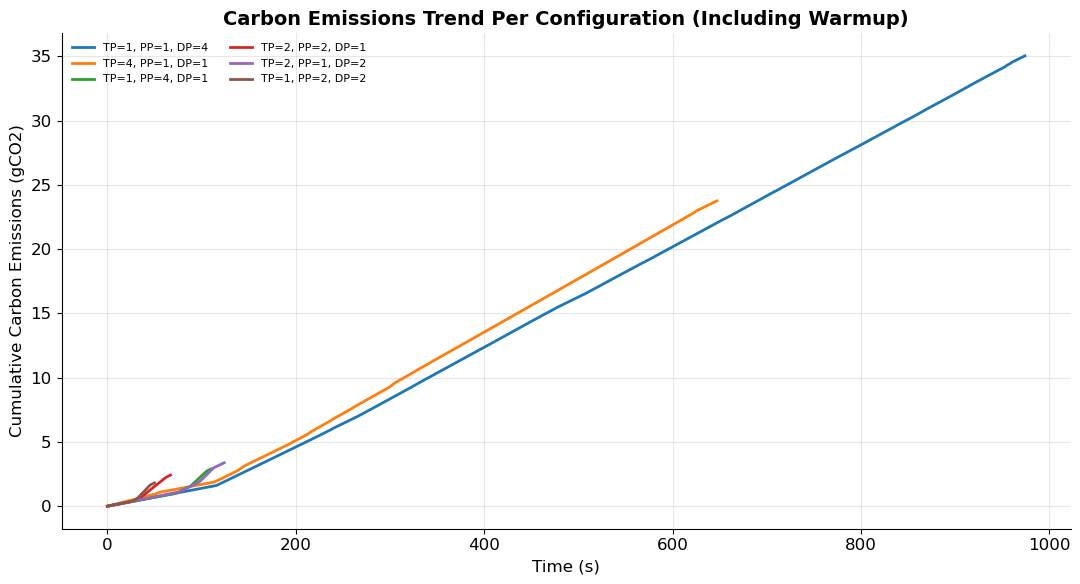

In [34]:
# Carbon trend plot in one chart: each line is a configuration over full run (including warmup).
INTERVAL_SECONDS = 0.5
CARBON_INTENSITY_G_PER_KWH_LOCAL = 400

fig, ax = plt.subplots(figsize=(11, 6))
for name, cfg in configs.items():
    df = cfg["df"].copy()
    x = np.arange(len(df)) * INTERVAL_SECONDS

    # Instantaneous emissions per sample (gCO2), then cumulative sum over time.
    grams_per_sample = (
        df["total_power_W"].to_numpy() * INTERVAL_SECONDS / 3_600_000
    ) * CARBON_INTENSITY_G_PER_KWH_LOCAL
    cumulative_grams = np.cumsum(grams_per_sample)

    ax.plot(
        x,
        cumulative_grams,
        linewidth=2.0,
        label=f"TP={cfg['tp']}, PP={cfg['pp']}, DP={cfg['dp']}"
    )

ax.set_xlabel("Time (s)", fontsize=12)
ax.set_ylabel("Cumulative Carbon Emissions (gCO2)", fontsize=12)
ax.set_title("Carbon Emissions Trend Per Configuration (Including Warmup)", fontsize=14, fontweight="bold")
ax.legend(fontsize=8, ncol=2, frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "graph0_carbon_trends_with_warmup.png"), dpi=150, bbox_inches="tight")
plt.show()


## 3) Shared Constants for Throughput and Carbon

In [35]:
CARBON_INTENSITY_G_PER_KWH = 400  # PJM grid (Pittsburgh, PA)

TRAIN_ITERS  = 50
GLOBAL_BATCH = 16
SEQ_LEN      = 1024
INTERVAL     = 0.5  # seconds per sample

all_configs = [
    ("DP=4\n(TP=1,PP=1)",  "dp",    configs["tp1_pp1_dp4"]),
    ("TP=4\n(PP=1,DP=1)",  "tp",    configs["tp4_pp1_dp1"]),
    ("PP=4\n(TP=1,DP=1)",  "pp",    configs["tp1_pp4_dp1"]),
    ("TP=2,PP=2\n(DP=1)",  "mixed", configs["tp2_pp2_dp1"]),
    ("TP=2,DP=2\n(PP=1)",  "mixed", configs["tp2_pp1_dp2"]),
    ("PP=2,DP=2\n(TP=1)",  "mixed", configs["tp1_pp2_dp2"]),
]

## 4) Graph 1-3: Single-axis Power vs DP/TP/PP

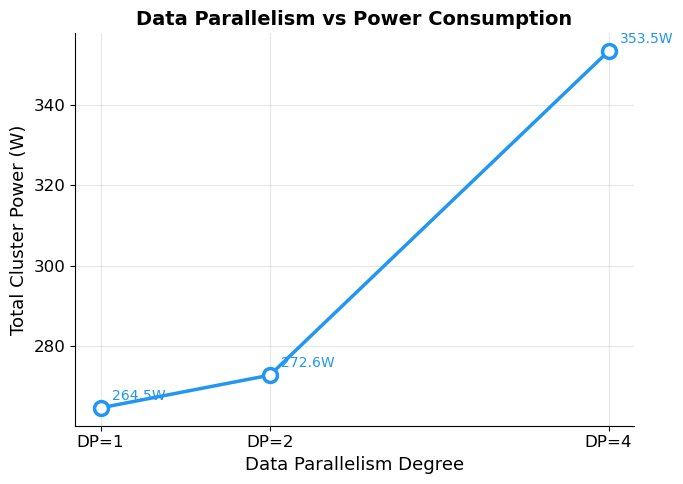

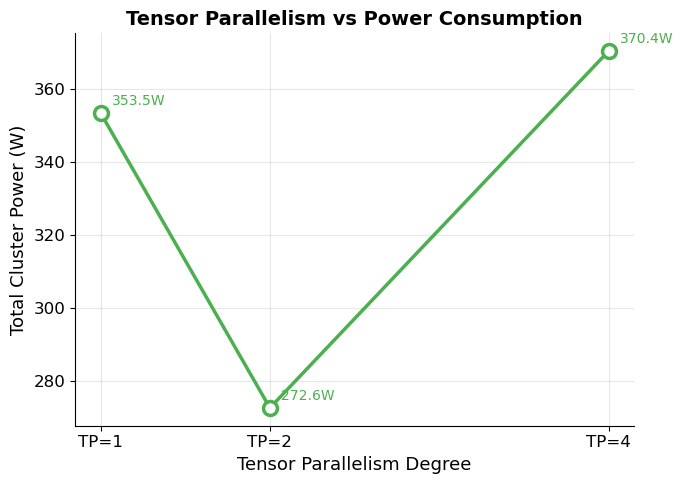

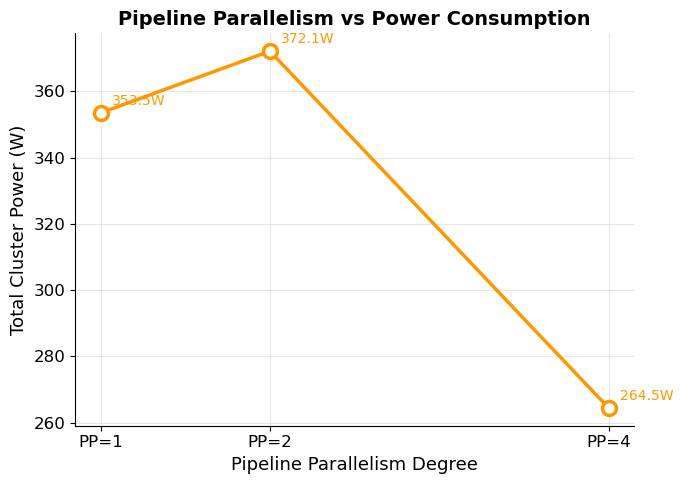

In [36]:
# Graph 1: DP vs Power
dp_data = [
    (1, configs["tp1_pp4_dp1"]["avg_power"]),
    (2, configs["tp2_pp1_dp2"]["avg_power"]),
    (4, configs["tp1_pp1_dp4"]["avg_power"]),
]
dp_x, dp_y = zip(*dp_data)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(dp_x, dp_y, "o-", color=COLORS["dp"], linewidth=2.5,
        markersize=10, markerfacecolor="white", markeredgewidth=2.5)
for x, y in dp_data:
    ax.annotate(f"{y:.1f}W", (x, y), textcoords="offset points",
                xytext=(8, 6), fontsize=10, color=COLORS["dp"])
ax.set_xlabel("Data Parallelism Degree", fontsize=13)
ax.set_ylabel("Total Cluster Power (W)", fontsize=13)
ax.set_title("Data Parallelism vs Power Consumption", fontsize=14, fontweight="bold")
ax.set_xticks([1, 2, 4])
ax.set_xticklabels(["DP=1", "DP=2", "DP=4"])
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "graph1_dp_vs_power.png"), dpi=150, bbox_inches="tight")
plt.show()

# Graph 2: TP vs Power
tp_data = [
    (1, configs["tp1_pp1_dp4"]["avg_power"]),
    (2, configs["tp2_pp1_dp2"]["avg_power"]),
    (4, configs["tp4_pp1_dp1"]["avg_power"]),
]
tp_x, tp_y = zip(*tp_data)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(tp_x, tp_y, "o-", color=COLORS["tp"], linewidth=2.5,
        markersize=10, markerfacecolor="white", markeredgewidth=2.5)
for x, y in tp_data:
    ax.annotate(f"{y:.1f}W", (x, y), textcoords="offset points",
                xytext=(8, 6), fontsize=10, color=COLORS["tp"])
ax.set_xlabel("Tensor Parallelism Degree", fontsize=13)
ax.set_ylabel("Total Cluster Power (W)", fontsize=13)
ax.set_title("Tensor Parallelism vs Power Consumption", fontsize=14, fontweight="bold")
ax.set_xticks([1, 2, 4])
ax.set_xticklabels(["TP=1", "TP=2", "TP=4"])
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "graph2_tp_vs_power.png"), dpi=150, bbox_inches="tight")
plt.show()

# Graph 3: PP vs Power
pp_data = [
    (1, configs["tp1_pp1_dp4"]["avg_power"]),
    (2, configs["tp1_pp2_dp2"]["avg_power"]),
    (4, configs["tp1_pp4_dp1"]["avg_power"]),
]
pp_x, pp_y = zip(*pp_data)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(pp_x, pp_y, "o-", color=COLORS["pp"], linewidth=2.5,
        markersize=10, markerfacecolor="white", markeredgewidth=2.5)
for x, y in pp_data:
    ax.annotate(f"{y:.1f}W", (x, y), textcoords="offset points",
                xytext=(8, 6), fontsize=10, color=COLORS["pp"])
ax.set_xlabel("Pipeline Parallelism Degree", fontsize=13)
ax.set_ylabel("Total Cluster Power (W)", fontsize=13)
ax.set_title("Pipeline Parallelism vs Power Consumption", fontsize=14, fontweight="bold")
ax.set_xticks([1, 2, 4])
ax.set_xticklabels(["PP=1", "PP=2", "PP=4"])
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "graph3_pp_vs_power.png"), dpi=150, bbox_inches="tight")
plt.show()

## 5) Graph 4: Power vs Throughput

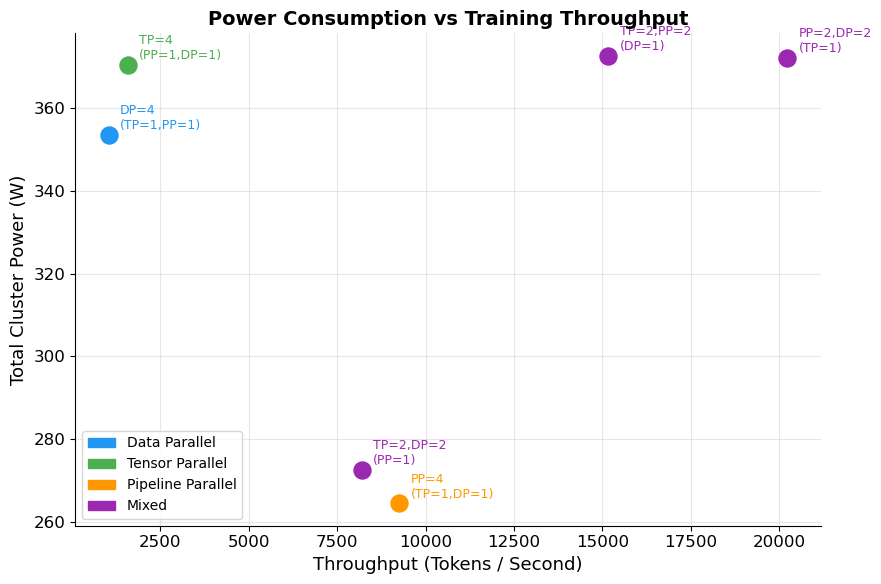

In [37]:
fig, ax = plt.subplots(figsize=(9, 6))
for label, ctype, cfg in all_configs:
    warmup = int(len(cfg["df"]) * 0.2)
    n_steady = len(cfg["df"]) - warmup
    train_time_s = n_steady * INTERVAL
    total_tokens = TRAIN_ITERS * GLOBAL_BATCH * SEQ_LEN
    tokens_per_sec = total_tokens / train_time_s

    ax.scatter(tokens_per_sec, cfg["avg_power"], color=COLORS[ctype], s=150, zorder=3)
    ax.annotate(label, (tokens_per_sec, cfg["avg_power"]),
                textcoords="offset points", xytext=(8, 4), fontsize=9, color=COLORS[ctype])

patches = [
    mpatches.Patch(color=COLORS["dp"], label="Data Parallel"),
    mpatches.Patch(color=COLORS["tp"], label="Tensor Parallel"),
    mpatches.Patch(color=COLORS["pp"], label="Pipeline Parallel"),
    mpatches.Patch(color=COLORS["mixed"], label="Mixed"),
]
ax.legend(handles=patches, fontsize=10, loc="best")
ax.set_xlabel("Throughput (Tokens / Second)", fontsize=13)
ax.set_ylabel("Total Cluster Power (W)", fontsize=13)
ax.set_title("Power Consumption vs Training Throughput", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "graph4_power_vs_tokens.png"), dpi=150, bbox_inches="tight")
plt.show()

## 6) Carbon Metrics Calculation

In [38]:
for label, ctype, cfg in all_configs:
    warmup = int(len(cfg["df"]) * 0.2)
    n_steady = len(cfg["df"]) - warmup
    train_time_s = n_steady * INTERVAL
    total_tokens = TRAIN_ITERS * GLOBAL_BATCH * SEQ_LEN
    tokens_per_sec = total_tokens / train_time_s
    energy_kwh = (cfg["avg_power"] * train_time_s) / 3_600_000
    carbon_g = energy_kwh * CARBON_INTENSITY_G_PER_KWH
    co2_per_1k = carbon_g / (total_tokens / 1000)

    cfg["tokens_per_sec"] = tokens_per_sec
    cfg["carbon_g"] = carbon_g
    cfg["co2_per_1k"] = co2_per_1k

    print(f"{label:25s} | {cfg['avg_power']:6.1f}W | {tokens_per_sec:8.1f} tok/s | {co2_per_1k:.4f} gCO₂/1k tokens")

DP=4
(TP=1,PP=1)          |  353.5W |   1050.3 tok/s | 0.0374 gCO₂/1k tokens
TP=4
(PP=1,DP=1)          |  370.4W |   1581.5 tok/s | 0.0260 gCO₂/1k tokens
PP=4
(TP=1,DP=1)          |  264.5W |   9256.5 tok/s | 0.0032 gCO₂/1k tokens
TP=2,PP=2
(DP=1)          |  372.6W |  15170.4 tok/s | 0.0027 gCO₂/1k tokens
TP=2,DP=2
(PP=1)          |  272.6W |   8192.0 tok/s | 0.0037 gCO₂/1k tokens
PP=2,DP=2
(TP=1)          |  372.1W |  20227.2 tok/s | 0.0020 gCO₂/1k tokens


## 7) Graph 5-7: Carbon Efficiency Views

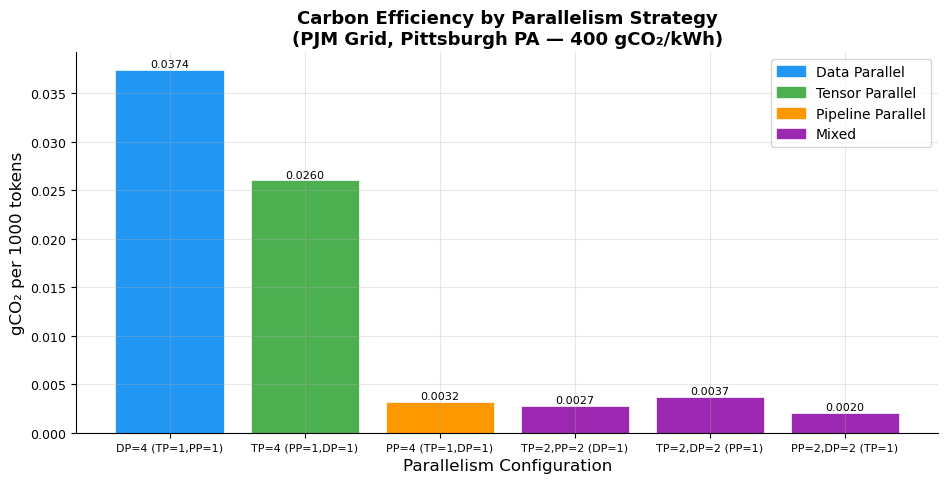

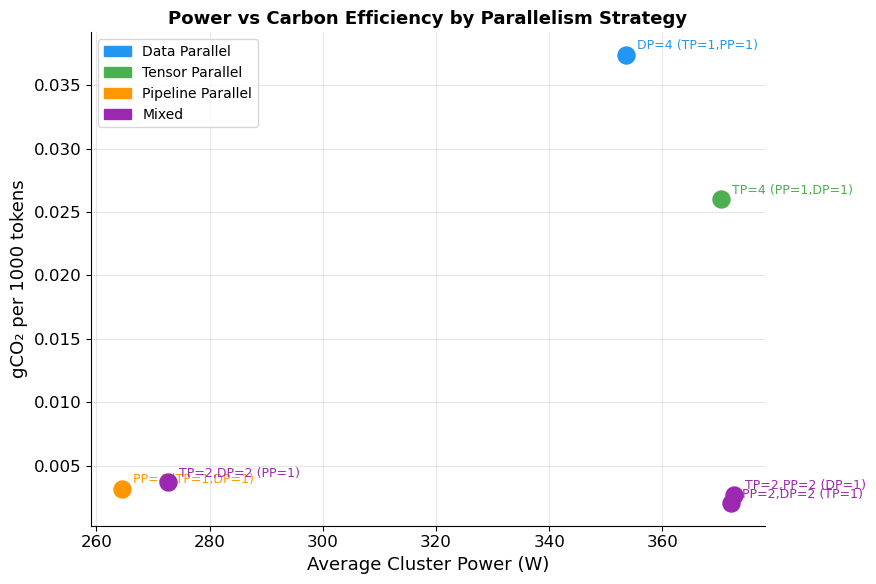

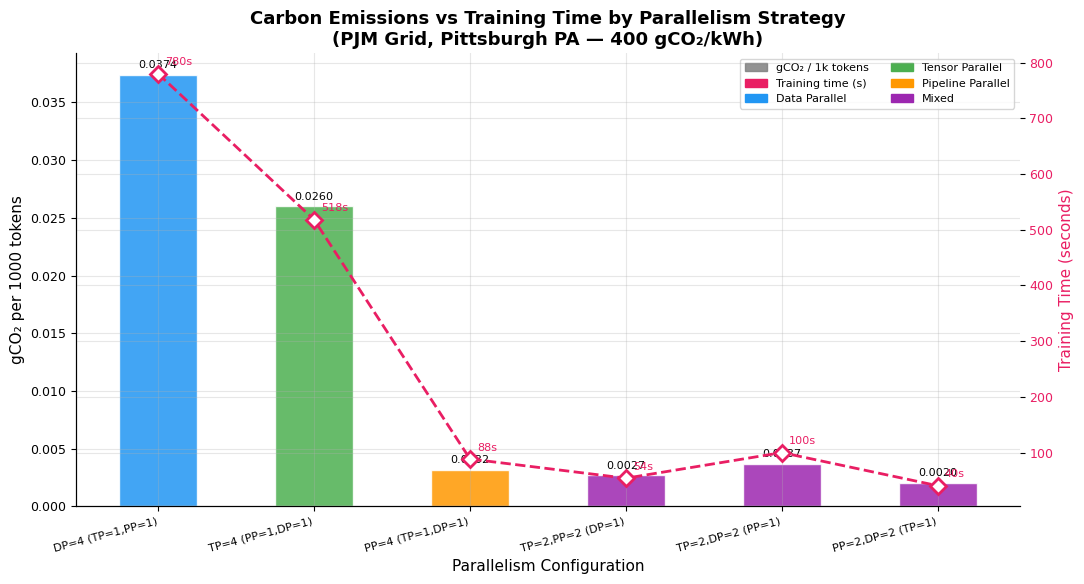

In [39]:
# Graph 5: Strategy vs gCO2/1000 tokens
labels = [c[0].replace("\n", " ") for c in all_configs]
co2vals = [c[2]["co2_per_1k"] for c in all_configs]
colors = [COLORS[c[1]] for c in all_configs]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(labels, co2vals, color=colors, edgecolor="white", linewidth=0.5)
for bar, val in zip(bars, co2vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0001,
            f"{val:.4f}", ha="center", va="bottom", fontsize=8)
ax.tick_params(axis="x", labelsize=8)
ax.tick_params(axis="y", labelsize=9)

patches = [
    mpatches.Patch(color=COLORS["dp"], label="Data Parallel"),
    mpatches.Patch(color=COLORS["tp"], label="Tensor Parallel"),
    mpatches.Patch(color=COLORS["pp"], label="Pipeline Parallel"),
    mpatches.Patch(color=COLORS["mixed"], label="Mixed"),
]
ax.legend(handles=patches, fontsize=10)
ax.set_ylabel("gCO₂ per 1000 tokens", fontsize=12)
ax.set_title("Carbon Efficiency by Parallelism Strategy\n(PJM Grid, Pittsburgh PA — 400 gCO₂/kWh)", fontsize=13, fontweight="bold")
ax.set_xlabel("Parallelism Configuration", fontsize=12)
plt.tight_layout()
plt.subplots_adjust(left=0.12)
plt.savefig(os.path.join(PLOTS_DIR, "graph5_carbon_per_1k_tokens.png"), dpi=150, bbox_inches="tight")
plt.show()

# Graph 6: Power vs Carbon Efficiency
fig, ax = plt.subplots(figsize=(9, 6))
for label, ctype, cfg in all_configs:
    ax.scatter(cfg["avg_power"], cfg["co2_per_1k"], color=COLORS[ctype], s=150, zorder=3)
    ax.annotate(label.replace("\n", " "),
                (cfg["avg_power"], cfg["co2_per_1k"]),
                textcoords="offset points", xytext=(8, 4),
                fontsize=9, color=COLORS[ctype])

ax.legend(handles=patches, fontsize=10)
ax.set_xlabel("Average Cluster Power (W)", fontsize=13)
ax.set_ylabel("gCO₂ per 1000 tokens", fontsize=13)
ax.set_title("Power vs Carbon Efficiency by Parallelism Strategy", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.subplots_adjust(left=0.12)
plt.savefig(os.path.join(PLOTS_DIR, "graph6_power_vs_carbon.png"), dpi=150, bbox_inches="tight")
plt.show()

# Graph 7: Carbon + Training Time (dual axis)
labels7 = [c[0].replace("\n", " ") for c in all_configs]
co2vals7 = [c[2]["co2_per_1k"] for c in all_configs]
colors7 = [COLORS[c[1]] for c in all_configs]
train_times = [
    (len(c[2]["df"]) - int(len(c[2]["df"]) * 0.2)) * INTERVAL
    for c in all_configs
]

x = np.arange(len(labels7))
width = 0.5

fig, ax1 = plt.subplots(figsize=(11, 6))

bars = ax1.bar(x, co2vals7, width, color=colors7,
               edgecolor="white", alpha=0.85, label="gCO₂ per 1k tokens")
for bar, val in zip(bars, co2vals7):
    ax1.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + max(co2vals7)*0.01,
             f"{val:.4f}", ha="center", va="bottom", fontsize=8)

ax1.set_ylabel("gCO₂ per 1000 tokens", fontsize=11, color="black")
ax1.tick_params(axis="y", labelcolor="black", labelsize=9)
ax1.tick_params(axis="x", labelsize=8)
ax1.set_xticks(x)
ax1.set_xticklabels(labels7, rotation=15, ha="right")

ax2 = ax1.twinx()
ax2.plot(x, train_times, "D--", color="#E91E63", linewidth=2,
         markersize=8, markerfacecolor="white", markeredgewidth=2,
         label="Training time (s)")
for i, t in enumerate(train_times):
    ax2.annotate(f"{t:.0f}s", (i, t),
                 textcoords="offset points", xytext=(5, 6),
                 fontsize=8, color="#E91E63")
ax2.set_ylabel("Training Time (seconds)", fontsize=11, color="#E91E63")
ax2.tick_params(axis="y", labelcolor="#E91E63", labelsize=9)

bars_patch = mpatches.Patch(color="gray", alpha=0.85, label="gCO₂ / 1k tokens")
line_patch = mpatches.Patch(color="#E91E63", label="Training time (s)")
type_patches = [
    mpatches.Patch(color=COLORS["dp"], label="Data Parallel"),
    mpatches.Patch(color=COLORS["tp"], label="Tensor Parallel"),
    mpatches.Patch(color=COLORS["pp"], label="Pipeline Parallel"),
    mpatches.Patch(color=COLORS["mixed"], label="Mixed"),
]
ax1.legend(handles=[bars_patch, line_patch] + type_patches,
           fontsize=8, loc="upper right", ncol=2)

ax1.set_title("Carbon Emissions vs Training Time by Parallelism Strategy\n(PJM Grid, Pittsburgh PA — 400 gCO₂/kWh)",
              fontsize=13, fontweight="bold")
ax1.set_xlabel("Parallelism Configuration", fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "graph7_carbon_vs_traintime.png"), dpi=150, bbox_inches="tight")
plt.show()

## 8) Graph 8-9: 3D Parallelism Space

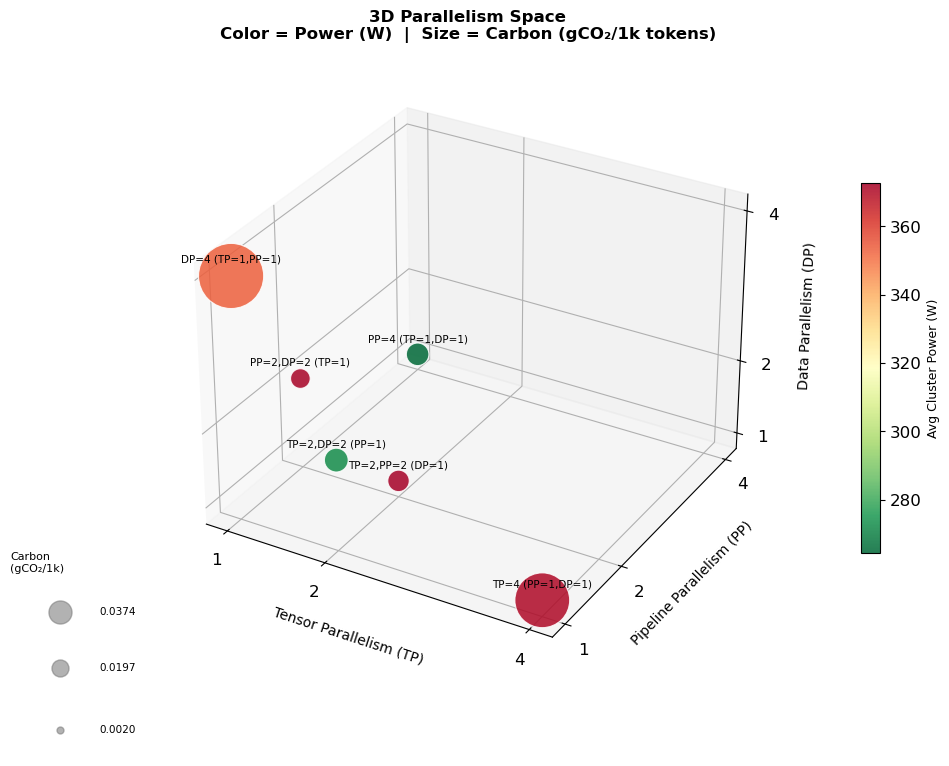

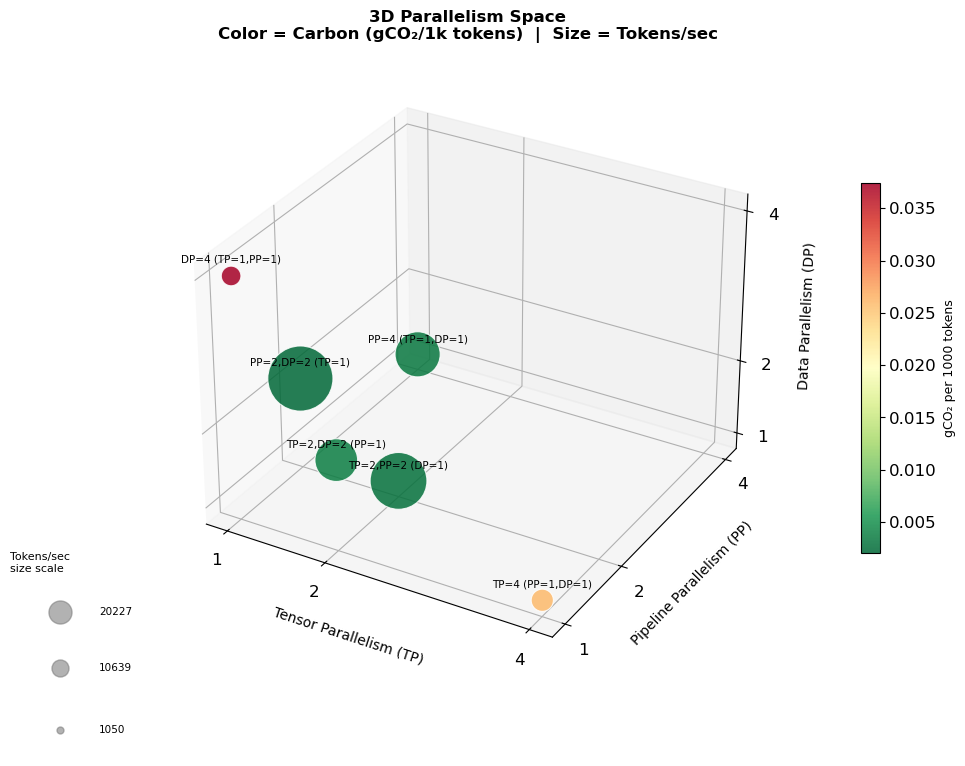

In [42]:
# Shared arrays for 3D plots
tp_vals = [c[2]["tp"] for c in all_configs]
pp_vals = [c[2]["pp"] for c in all_configs]
dp_vals = [c[2]["dp"] for c in all_configs]
power_vals = [c[2]["avg_power"] for c in all_configs]
co2_vals = [c[2]["co2_per_1k"] for c in all_configs]
lbls = [c[0].replace("\n", " ") for c in all_configs]

p_min, p_max = min(power_vals), max(power_vals)
c_min, c_max = min(co2_vals), max(co2_vals)

# Graph 8: color=power, size=carbon
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

norm = plt.Normalize(vmin=p_min, vmax=p_max)
cmap = cm.RdYlGn_r
sizes = [200 + 2000 * (c - c_min) / (c_max - c_min + 1e-9) for c in co2_vals]

sc = ax.scatter(tp_vals, pp_vals, dp_vals,
                c=power_vals, cmap=cmap,
                s=sizes, alpha=0.85, edgecolors="white", linewidths=0.8,
                vmin=p_min, vmax=p_max)

for tp, pp, dp, lbl in zip(tp_vals, pp_vals, dp_vals, lbls):
    ax.text(tp, pp, dp + 0.15, lbl, fontsize=7.5,
            ha="center", va="bottom", color="black")

ax.set_xlabel("Tensor Parallelism (TP)", fontsize=10, labelpad=8)
ax.set_ylabel("Pipeline Parallelism (PP)", fontsize=10, labelpad=8)
ax.set_zlabel("Data Parallelism (DP)", fontsize=10, labelpad=8)
ax.set_xticks([1, 2, 4])
ax.set_yticks([1, 2, 4])
ax.set_zticks([1, 2, 4])
ax.set_title("3D Parallelism Space\nColor = Power (W)  |  Size = Carbon (gCO₂/1k tokens)",
             fontsize=12, fontweight="bold", pad=15)

cbar = fig.colorbar(sc, ax=ax, pad=0.1, shrink=0.6)
cbar.set_label("Avg Cluster Power (W)", fontsize=9)

legend_ax = fig.add_axes([0.01, 0.01, 0.18, 0.22])
legend_ax.set_xlim(0, 1)
legend_ax.set_ylim(0, 1)
legend_ax.axis("off")
legend_ax.set_title("Carbon\n(gCO₂/1k)", fontsize=8, loc="left")

sample_co2 = [c_min, (c_min + c_max) / 2, c_max]
sample_y = [0.15, 0.50, 0.82]
for co2, y in zip(sample_co2, sample_y):
    sz = 200 + 2000 * (co2 - c_min) / (c_max - c_min + 1e-9)
    legend_ax.scatter([0.25], [y], s=sz/8, c="gray", alpha=0.6)
    legend_ax.text(0.45, y, f"{co2:.4f}", va="center", fontsize=7.5)

#plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "graph8_3d_parallelism.png"), dpi=150, bbox_inches="tight")
plt.show()

# Graph 9: color=carbon, size=tokens/sec
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

toks_vals = [c[2]["tokens_per_sec"] for c in all_configs]
t_min, t_max = min(toks_vals), max(toks_vals)

norm2 = plt.Normalize(vmin=c_min, vmax=c_max)
cmap2 = cm.RdYlGn_r
sizes2 = [200 + 2000 * (t - t_min) / (t_max - t_min + 1e-9) for t in toks_vals]

sc2 = ax.scatter(tp_vals, pp_vals, dp_vals,
                 c=co2_vals, cmap=cmap2,
                 s=sizes2, alpha=0.85, edgecolors="white", linewidths=0.8,
                 vmin=c_min, vmax=c_max)

for tp, pp, dp, lbl in zip(tp_vals, pp_vals, dp_vals, lbls):
    ax.text(tp, pp, dp + 0.15, lbl, fontsize=7.5,
            ha="center", va="bottom", color="black")

ax.set_xlabel("Tensor Parallelism (TP)", fontsize=10, labelpad=8)
ax.set_ylabel("Pipeline Parallelism (PP)", fontsize=10, labelpad=8)
ax.set_zlabel("Data Parallelism (DP)", fontsize=10, labelpad=8)
ax.set_xticks([1, 2, 4])
ax.set_yticks([1, 2, 4])
ax.set_zticks([1, 2, 4])
ax.set_title("3D Parallelism Space\nColor = Carbon (gCO₂/1k tokens)  |  Size = Tokens/sec",
             fontsize=12, fontweight="bold", pad=15)

cbar2 = fig.colorbar(sc2, ax=ax, pad=0.1, shrink=0.6)
cbar2.set_label("gCO₂ per 1000 tokens", fontsize=9)

legend_ax2 = fig.add_axes([0.01, 0.01, 0.18, 0.22])
legend_ax2.set_xlim(0, 1)
legend_ax2.set_ylim(0, 1)
legend_ax2.axis("off")
legend_ax2.set_title("Tokens/sec\nsize scale", fontsize=8, loc="left")
for tok, y in zip([t_min, (t_min + t_max) / 2, t_max], [0.15, 0.50, 0.82]):
    sz = 200 + 2000 * (tok - t_min) / (t_max - t_min + 1e-9)
    legend_ax2.scatter([0.25], [y], s=sz/8, c="gray", alpha=0.6)
    legend_ax2.text(0.45, y, f"{tok:.0f}", va="center", fontsize=7.5)

#plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "graph9_3d_carbon_tokens.png"), dpi=150, bbox_inches="tight")
plt.show()

# Carbon efficiency in 3D parallelism space (how much tokens per second are we gaining per unit of carbon emitted)

In [ ]:
# Graph 10: 3D carbon efficiency plot (color only)
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

# Convert carbon cost (gCO2/1k tokens) into an efficiency score so bigger is better.
carbon_eff_vals = [1.0 / (cfg["co2_per_1k"] + 1e-12) for _, _, cfg in all_configs]
e_min, e_max = min(carbon_eff_vals), max(carbon_eff_vals)
sc3 = ax.scatter(tp_vals, pp_vals, dp_vals,
                 s=320, c=carbon_eff_vals, cmap=cm.Greens,
                 alpha=0.85, edgecolors="white", linewidths=0.8,
                 vmin=e_min, vmax=e_max)

for tp, pp, dp, lbl in zip(tp_vals, pp_vals, dp_vals, lbls):
    ax.text(tp, pp, dp + 0.15, lbl, fontsize=7.5,
            ha="center", va="bottom", color="black")

ax.set_xlabel("Tensor Parallelism (TP)", fontsize=10, labelpad=8)
ax.set_ylabel("Pipeline Parallelism (PP)", fontsize=10, labelpad=8)
ax.set_zlabel("Data Parallelism (DP)", fontsize=10, labelpad=8)
ax.set_xticks([1, 2, 4])
ax.set_yticks([1, 2, 4])
ax.set_zticks([1, 2, 4])
ax.set_title("3D Parallelism Space\nColor = Carbon Efficiency (1 / gCO2 per 1k tokens)  [Greener is better]",
             fontsize=12, fontweight="bold", pad=15)

cbar3 = fig.colorbar(sc3, ax=ax, pad=0.1, shrink=0.6)
cbar3.set_label("Carbon Efficiency (1 / gCO2 per 1k tokens)  [Greener is better]", fontsize=9)

plt.savefig(os.path.join(PLOTS_DIR, "graph10_3d_carbon_efficiency_color_only.png"), dpi=150, bbox_inches="tight")
plt.show()